# 02 — Taxa manual

**Pergunta de negócio.** Para um grupo sem histórico próprio (cotação nova), qual a mortalidade esperada
em relação à BR-EMSmt 2026, e quais características do grupo mudam esse nível?

**Modelo.** Em cada célula (estipulante × faixa etária × sexo × setor × faixa de capital × porte):

N ~ Poisson(μ), com log μ = log E + β₀ + efeitos dos fatores,

em que E são os óbitos esperados pela tábua. exp(β) é um fator A/E relativo; o nível base de cada fator
é o de maior exposição.

**Decisões (justificadas abaixo):**
1. Estima-se em **contagem de óbitos**, não em valor: em R$, poucos sinistros de capital alto
   dominariam os fatores. O valor entra na renovação (Etapa 3), com pooling de sinistros grandes.
2. Só entra experiência **maturada** (até 12 meses antes da data de referência), para o IBNR não
   puxar os fatores para baixo.
3. O modelo final tem **efeito aleatório de estipulante** (Poisson-Gama). Ele separa o efeito do
   setor do efeito do grupo, dá intervalos de confiança honestos e estima o k de credibilidade
   usado na renovação.
4. Um fator só entra na tabela de preço com evidência estatística (teste de razão de verossimilhança).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm = carregar_config("base", RAIZ), carregar_config("manual", RAIZ)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder, "Tábua oficial não carregada"

pasta = RAIZ / "data/synthetic/limpo"
if not pasta.exists():
    raise FileNotFoundError("Rode antes o notebook 01_dados (ele grava a base limpa em data/synthetic/limpo).")
dados = {t: pd.read_parquet(pasta / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
verdade = pd.read_parquet(RAIZ / "data/synthetic/verdade_estipulantes.parquet")
cs = carregar_config("sintetico", RAIZ)
print(f"Tábua: {tabua.nome} | estipulantes: {len(dados['estipulantes'])} | segmentos de vida: {len(dados['vidas']):,}")

Tábua: BR-EMSmt-2026 | estipulantes: 250 | segmentos de vida: 711,103


## 1. Base de modelagem

In [2]:
cel, info = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                             cfg["data_referencia"], cm, cfg["exposicao"]["dias_por_ano"])
pd.Series({k: v for k, v in info.items() if k != "ids_sem_celula"}).to_frame("valor")

,valor
corte_experiencia,2024-12-31
sinistros_no_periodo,1424
sinistros_sem_celula,21
celulas_sexo_ND_removidas,1045
celulas,6440
obitos,1396
esperados,"1,443.2470"


Sinistros "sem célula" são os de vidas que não têm exposição limpa na data do óbito (vida
inexistente no cadastro, ou segmento excluído na validação). Ficam fora do modelo e estão listados
em `info["ids_sem_celula"]` para investigação. Células com sexo ausente também ficam fora.

## 2. Primeira leitura: A/E por fator, sem ajuste

In [3]:
F = cm["fatores"]
uni = pd.concat([cel.groupby(f, observed=True)[["E", "N"]].sum().assign(fator=f).rename_axis("nivel").reset_index()
                 for f in F])
uni["A/E"] = uni["N"] / uni["E"]
uni[["fator", "nivel", "E", "N", "A/E"]]

,fator,nivel,E,N,A/E
0,faixa_idade,30-39,268.9079,267,0.9929
1,faixa_idade,40-49,439.8466,421,0.9572
2,faixa_idade,50-59,404.6047,396,0.9787
3,faixa_idade,60+,201.8413,208,1.0305
4,faixa_idade,ate29,128.0465,104,0.8122
0,sexo,F,454.8225,410,0.9015
1,sexo,M,988.4245,986,0.9975
0,setor,adm_publica,300.3063,263,0.8758
1,setor,comercio,124.1389,106,0.8539
2,setor,construcao,106.7399,138,1.2929


A/E univariado mistura efeitos (um setor com grupos de capital alto parece melhor também por causa do
capital). O modelo multivariado separa isso.

## 3. GLM Poisson e teste de sobredispersão

In [4]:
glm = M.ajustar_glm(cel, F)
nb = M.teste_binomial_negativa(cel, F, glm)
pd.Series({"deviance": glm.extra["deviance"], "gl": glm.extra["gl"],
           "dispersão de Pearson": glm.extra["dispersao_pearson"],
           "alpha NB2": nb["alpha_nb2"], "LR NB vs Poisson": nb["estatistica_lr"],
           "p-valor (mistura 50:50)": nb["p_valor"], "AIC Poisson": nb["aic_poisson"], "AIC NB": nb["aic_nb"]}).to_frame("valor")

,valor
deviance,"2,604.1445"
gl,"6,421.0000"
dispersão de Pearson,1.8573
alpha NB2,0.0714
LR NB vs Poisson,5.2412
p-valor (mistura 50:50),0.0110
AIC Poisson,"4,432.2979"
AIC NB,"4,429.0567"


Há sobredispersão em relação à Poisson. A Binomial Negativa trata isso como ruído genérico por
célula. Mas a fonte real é conhecida: grupos diferentes têm mortalidades diferentes, e todas as
células de um grupo compartilham esse desvio. O modelo certo coloca o efeito **no grupo**.

## 4. Poisson-Gama: efeito aleatório de estipulante

Cada estipulante tem um fator u ~ Gama(média 1, variância 1/k). A verossimilhança marginal tem forma
fechada (sem aproximação numérica), e a média a posteriori de u é exatamente a fórmula de credibilidade:

E[u | dados] = Z · (N/M) + (1 − Z),   Z = M / (M + k),

em que M são os óbitos esperados pela taxa manual. **k é medido em óbitos esperados**: um grupo com
M = k óbitos esperados recebe 50% de credibilidade.

In [5]:
pg = M.ajustar_poisson_gama(cel, F, beta_inicial=glm.beta)
k_verdade = 1 / (np.exp(cs["sigma_efeito_grupo"] ** 2) - 1)
pd.Series({"k estimado": pg.extra["k"], "IC 95% inferior": pg.extra["ic_k"][0], "IC 95% superior": pg.extra["ic_k"][1],
           "CV do efeito de grupo": pg.extra["cv_efeito_grupo"],
           "k implícito na hipótese do gerador": k_verdade,
           "óbitos esperados p/ Z = 50%": pg.extra["k"],
           "óbitos esperados p/ Z = 80%": 4 * pg.extra["k"]}).to_frame("valor")

,valor
k estimado,9.3405
IC 95% inferior,5.4223
IC 95% superior,16.0899
CV do efeito de grupo,0.3272
k implícito na hipótese do gerador,10.6186
óbitos esperados p/ Z = 50%,9.3405
óbitos esperados p/ Z = 80%,37.3619


In [6]:
taxa = cel["E"].sum() / cel["exposicao"].sum()       # óbitos esperados por vida-ano na carteira
k = pg.extra["k"]
print(f"Mortalidade média esperada: {1000 * taxa:.2f} por mil vidas-ano")
print(f"Z = 50%: ~{k:.0f} óbitos esperados  ≈ {k / taxa:,.0f} vidas-ano")
print(f"Z = 80%: ~{4 * k:.0f} óbitos esperados ≈ {4 * k / taxa:,.0f} vidas-ano")

Mortalidade média esperada: 1.77 por mil vidas-ano
Z = 50%: ~9 óbitos esperados  ≈ 5,269 vidas-ano
Z = 80%: ~37 óbitos esperados ≈ 21,077 vidas-ano


Em termos de negócio: um grupo precisa de milhares de vidas-ano para que a própria experiência pese
metade na estimativa. A maioria dos grupos de vida fica longe disso, o que explica por que a taxa manual
pesa tanto na renovação.

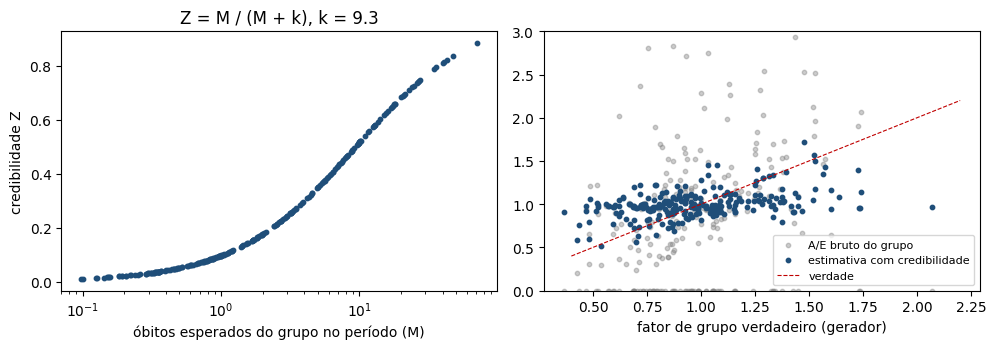

Erro (RMSE em log, ponderado por M): A/E bruto = 0.648 | com credibilidade = 0.204


In [7]:
g = pg.extra["grupos"].merge(verdade[["id_estipulante", "fator_grupo"]], on="id_estipulante")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(g["M"], g["Z"], s=10, color="#1f4e79"); ax[0].set_xscale("log")
ax[0].set_xlabel("óbitos esperados do grupo no período (M)"); ax[0].set_ylabel("credibilidade Z")
ax[0].set_title(f"Z = M / (M + k), k = {pg.extra['k']:.1f}")
ae_bruto = g["N"] / g["M"]
ax[1].scatter(g["fator_grupo"], ae_bruto, s=10, alpha=0.4, color="grey", label="A/E bruto do grupo")
ax[1].scatter(g["fator_grupo"], g["fator_grupo_posteriori"], s=10, color="#1f4e79", label="estimativa com credibilidade")
ax[1].plot([0.4, 2.2], [0.4, 2.2], ls="--", color="#c00000", lw=0.8, label="verdade")
ax[1].set_ylim(0, 3); ax[1].set_xlabel("fator de grupo verdadeiro (gerador)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
erro = lambda x: np.sqrt(np.average((np.log(x.clip(0.05)) - np.log(g["fator_grupo"])) ** 2, weights=g["M"]))
print(f"Erro (RMSE em log, ponderado por M): A/E bruto = {erro(ae_bruto):.3f} | com credibilidade = {erro(g['fator_grupo_posteriori']):.3f}")

O gráfico da direita é o argumento da Etapa 3 em uma imagem: o A/E bruto de grupos pequenos espalha
muito (inclusive zeros), e a estimativa com credibilidade fica bem mais perto do fator verdadeiro.

## 5. Ridge (penalização) com λ escolhido deixando grupos de fora

In [8]:
cvl = M.escolher_lambda(cel, F, cm["ridge"]["lambdas"], cm["ridge"]["folds"], cm["semente_cv"])
lam = float(cvl.loc[cvl["deviance_fora_amostra"].idxmin(), "lambda"])
rid = M.ajustar_ridge(cel, F, lam)
print("lambda escolhido:", lam); cvl

lambda escolhido: 100.0


,lambda,deviance_fora_amostra,dif_vs_melhor
0,0.0000,459.1013,14.8647
1,1.0000,458.4535,14.2168
2,3.0000,457.2663,13.0297
3,10.0000,454.0423,9.8057
4,30.0000,448.8660,4.6294
5,100.0000,444.2366,0.0000
6,300.0000,444.8799,0.6433


## 6. Fatores: GLM vs Poisson-Gama vs Ridge (e a verdade do gerador)

In [9]:
fg, fp, fr = glm.fatores(), pg.fatores(), rid.fatores()
comp = (fg[["fator", "nivel", "relatividade", "ic_inf", "ic_sup"]]
        .merge(fp[["fator", "nivel", "relatividade", "ic_inf", "ic_sup"]], on=["fator", "nivel"], suffixes=("_glm", "_pg"))
        .merge(fr[["fator", "nivel", "relatividade"]].rename(columns={"relatividade": "relatividade_ridge"}), on=["fator", "nivel"]))
comp

,fator,nivel,relatividade_glm,ic_inf_glm,ic_sup_glm,relatividade_pg,ic_inf_pg,ic_sup_pg,relatividade_ridge
0,faixa_idade,30-39,1.0526,0.9023,1.2280,1.0536,0.9031,1.2291,1.0339
1,faixa_idade,40-49,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,faixa_idade,50-59,1.0124,0.8816,1.1625,1.0137,0.8827,1.1640,1.0122
3,faixa_idade,60+,1.0713,0.9030,1.2710,1.0729,0.9042,1.2731,1.0482
4,faixa_idade,ate29,0.8776,0.7064,1.0904,0.8781,0.7068,1.0910,0.9284
5,sexo,F,1.0047,0.8905,1.1334,1.0031,0.8891,1.1317,0.9672
6,sexo,M,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,setor,adm_publica,0.9469,0.7991,1.1221,0.9096,0.6871,1.2041,0.9802
8,setor,comercio,1.0324,0.8237,1.2938,1.0993,0.8190,1.4754,1.0402
9,setor,construcao,1.4911,1.2167,1.8272,1.4489,1.0454,2.0082,1.2756


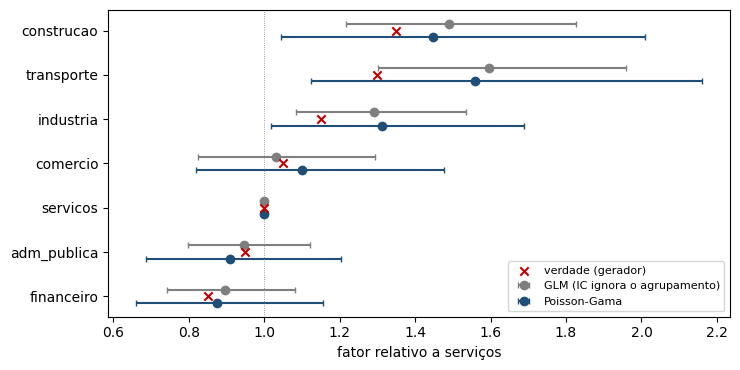

In [10]:
s = comp[comp["fator"] == "setor"].copy()
v = pd.Series({k: x["fator_mortalidade"] for k, x in cs["setores"].items()})
s["verdade"] = s["nivel"].map(v / v["servicos"])        # verdade relativa ao nível base (serviços)
s = s.sort_values("verdade")
fig, ax = plt.subplots(figsize=(7.5, 3.8)); y = np.arange(len(s))
ax.errorbar(s["relatividade_glm"], y + 0.15, xerr=[s["relatividade_glm"] - s["ic_inf_glm"], s["ic_sup_glm"] - s["relatividade_glm"]],
            fmt="o", color="#7f7f7f", capsize=2, label="GLM (IC ignora o agrupamento)")
ax.errorbar(s["relatividade_pg"], y - 0.15, xerr=[s["relatividade_pg"] - s["ic_inf_pg"], s["ic_sup_pg"] - s["relatividade_pg"]],
            fmt="o", color="#1f4e79", capsize=2, label="Poisson-Gama")
ax.scatter(s["verdade"], y, marker="x", color="#c00000", zorder=5, label="verdade (gerador)")
ax.set_yticks(y, s["nivel"]); ax.axvline(1, color="grey", lw=0.6, ls=":")
ax.set_xlabel("fator relativo a serviços"); ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Os pontos estimados do GLM e do Poisson-Gama são parecidos. O que muda é o **intervalo**: o GLM trata
cada célula como independente e fica confiante demais, porque as células do mesmo grupo compartilham o
desvio do grupo. O estudo de simulação (seção 8) mede isso.

## 7. Quais fatores entram na tabela de preço

In [11]:
selecionados, historico = M.selecionar_fatores(cel, F, alfa=0.05)
print("Fatores selecionados:", selecionados)
historico

Fatores selecionados: ['setor']


,fator,niveis,estatistica_lr,gl,p_valor,passo,acao
0,faixa_idade,5,3.2413,4,0.5183,1,
1,sexo,2,0.0026,1,0.9596,1,retirado
2,setor,7,17.4415,6,0.0078,1,
3,faixa_capital,5,1.8199,4,0.7688,1,
4,faixa_tamanho,4,1.1707,3,0.7600,1,
5,faixa_idade,5,3.2542,4,0.5162,2,
6,setor,7,17.7920,6,0.0068,2,
7,faixa_capital,5,1.8199,4,0.7688,2,retirado
8,faixa_tamanho,4,1.1706,3,0.7601,2,
9,faixa_idade,5,3.2641,4,0.5146,3,


Idade e sexo já estão na tábua; o teste pergunta se há desvio **adicional** em relação a ela. Na
carteira sintética não há (o gerador usa a própria tábua por idade e sexo), e o teste corretamente não os
inclui. A faixa de capital tem um efeito real no gerador (gradiente de renda), mas fraco demais para ser
detectado com ~1.400 óbitos: o teste não o rejeita por falta de poder, não por ausência de efeito. Na base
real, com mais anos e mais vidas, esse é o primeiro fator a reavaliar.

## 8. Estudo de simulação: a complexidade muda o preço?

Doze carteiras sintéticas independentes, mesmas hipóteses, sementes diferentes
(`scripts/estudo_simulacao_manual.py`, ~6 minutos). Métricas: erro dos fatores de setor contra a
verdade, cobertura real do IC de 95% e deviance fora da amostra deixando grupos inteiros de fora (o caso
de uso da taxa manual: cotar um grupo que o modelo nunca viu).

In [12]:
est = pd.read_csv(RAIZ / "resultados/estudo_simulacao_manual.csv")
res_est = est.groupby("modelo").agg(rmse_log_setor=("rmse_log_setor", "mean"),
                                    cobertura_ic95=("cobertura_ic95_setor", "mean"),
                                    deviance_fora_amostra=("deviance_fora_amostra", "mean"),
                                    k_medio=("k", "mean"), k_ic_cobre_verdade=("k_ic_cobre_verdade", "mean"))
res_est.sort_values("deviance_fora_amostra")

,rmse_log_setor,cobertura_ic95,deviance_fora_amostra,k_medio,k_ic_cobre_verdade
modelo,,,,,
Ridge,0.1148,NaN,434.0127,NaN,NaN
Poisson-Gama (só setor),0.1181,0.9444,434.0365,12.5890,1.0000
BR-EMS pura,0.1731,NaN,445.1298,NaN,NaN
Poisson-Gama (todos),0.1196,0.9259,453.3360,12.6412,1.0000
GLM (todos os fatores),0.1290,0.7963,455.6832,NaN,NaN


**Leitura:**
- **GLM com todos os fatores** erra menos que a tábua pura nos fatores de setor, mas prevê grupos novos
  *pior* que a própria tábua (deviance maior): fatores sem efeito real só acrescentam ruído. E o IC de 95%
  dele cobre a verdade em só ~80% dos casos.
- **Poisson-Gama com fatores selecionados** prevê grupos novos melhor que todos os outros com IC (ganha do
  GLM em 11 de 12 carteiras), e o IC tem cobertura próxima da nominal.
- **Ridge** empata com o Poisson-Gama selecionado na previsão. É a alternativa quando há muitos níveis
  esparsos (por exemplo, CNAE detalhado na base real), mas não produz IC nem k.
- **k:** o intervalo cobriu o valor implícito no gerador nas 12 carteiras; a média (≈12,6) fica um pouco
  acima de 10,6, porque o gerador usa efeito lognormal e o modelo assume Gama. Viés pequeno e na direção
  conservadora (k maior = menos credibilidade à experiência).

**Decisão:** a taxa manual usa o **Poisson-Gama com os fatores selecionados**. A complexidade (efeito de
grupo) entra porque muda duas coisas que importam: o preço de grupos novos fica melhor que o do GLM, e o
mesmo modelo entrega o k da renovação.

## 9. Modelo final e tabela de fatores para o cotador

In [13]:
final = M.ajustar_poisson_gama(cel, selecionados)
meta = {"gerado_em": pd.Timestamp.today().date().isoformat(), "fonte_dados": "carteira sintética",
        "tabua": tabua.nome, "tabua_sha256": tabua.sha256, "corte_experiencia": info["corte_experiencia"],
        "obitos": info["obitos"], "esperados_tabua": round(info["esperados"], 2),
        "k_credibilidade": round(final.extra["k"], 3),
        "k_ic95": [round(x, 3) for x in final.extra["ic_k"]],
        "selecao": "eliminação para trás, razão de verossimilhança, alfa = 5%",
        "fatores_testados": F, "faixas": cm["faixas"]}
tabela = M.tabela_fatores(final, meta)
M.salvar_tabela(tabela, RAIZ / "artefatos/fatores_manual.yaml")
print("A/E base:", round(tabela["meta"]["ae_base"], 4)); final.fatores()

A/E base: 0.8664


,fator,nivel,base,relatividade,ep_log,ic_inf,ic_sup
0,setor,adm_publica,False,0.9445,0.1398,0.7182,1.2421
1,setor,comercio,False,1.0530,0.1445,0.7932,1.3977
2,setor,construcao,False,1.4557,0.1623,1.0591,2.0009
3,setor,financeiro,False,0.8681,0.1411,0.6583,1.1447
4,setor,industria,False,1.2761,0.1256,0.9976,1.6323
5,setor,servicos,True,1.0000,0.0000,1.0000,1.0000
6,setor,transporte,False,1.5812,0.1588,1.1583,2.1584


## 10. Exemplo: taxa pura manual de um grupo

In [14]:
ref = pd.Timestamp(cfg["data_referencia"])
v = dados["vidas"]
ativos = v[v["data_fim"].isna()]
grupo = ativos["id_estipulante"].value_counts().index[len(ativos["id_estipulante"].unique()) // 2]   # um grupo médio
censo = ativos[ativos["id_estipulante"] == grupo]
setor = dados["estipulantes"].set_index("id_estipulante").loc[grupo, "setor"]
cot = M.taxa_pura_manual(censo, setor, tabela, tabua, ref + pd.Timedelta(days=1), cm)
pd.Series({"estipulante": grupo, "setor": setor, "vidas": cot["vidas"], "capital total (R$)": cot["capital_total"],
           "óbitos esperados/ano": cot["obitos_esperados"], "prêmio puro anual (R$)": cot["premio_puro_anual"],
           "taxa pura anual (‰)": cot["taxa_pura_anual_mil"], "taxa pura mensal (‰)": cot["taxa_pura_mensal_mil"],
           "níveis sem fator": cot["niveis_sem_fator"] or "nenhum"}).to_frame("cotação")

,cotação
estipulante,EST0192
setor,industria
vidas,293
capital total (R$),"29,300,000.0000"
óbitos esperados/ano,0.7268
prêmio puro anual (R$),"72,684.5132"
taxa pura anual (‰),2.4807
taxa pura mensal (‰),0.2067
níveis sem fator,nenhum


A taxa comercial (carregamentos, impostos, corretagem) e o reajuste de renovação entram no cotador
e na Etapa 3.

## Limitações e próximos passos
- **Dados sintéticos:** a escolha de fatores aqui reflete as hipóteses do gerador. Com a base real, a
  seleção roda de novo, com o mesmo critério; o código não muda.
- **Poder estatístico:** fatores com efeito pequeno (como capital) podem não ser detectados. Na base real
  vale combinar o teste com julgamento atuarial e com a visão em valor (Etapa 3).
- **Efeito Gama vs lognormal:** o modelo assume Gama; o estudo mostra viés pequeno e conservador no k.
- **Tamanho do grupo:** não teve efeito na mortalidade. Se o mercado diferencia preço por porte, isso é
  despesa (carregamento), não mortalidade, e vai como parâmetro no cotador.